In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import classification_report, roc_auc_score

# Load the cleaned dataset
df = pd.read_csv('../training_data_temporal_corrected.csv', low_memory=False)

# Drop rows where the target is missing
df = df.dropna(subset=['target']).copy()
df['target'] = df['target'].astype(int)

print(f"Data loaded successfully. Total eligible interactions: {len(df)}")

Data loaded successfully. Total eligible interactions: 71387


In [4]:
# First, let's list the features we actually care about
features_to_use = [
    'num_pages',
    'average_rating',
    'publication_year',
    'previous_interactions',
    'previous_conversions_90d',
    'user_conversion_rate_90d',
    'user_avg_rating',
    'user_avg_pages_read',
    'num_canonical_genres'
]

# Make sure we only check columns that exist in the file
actual_features = [col for col in features_to_use if col in df.columns]

# Print out the count of missing (NaN) values for each column
print("--- Missing Values Count Before Filling ---")
print(df[actual_features].isnull().sum())

--- Missing Values Count Before Filling ---
num_pages                       0
average_rating                  3
publication_year            10453
previous_interactions           0
previous_conversions_90d        0
user_conversion_rate_90d    13525
user_avg_rating             27336
user_avg_pages_read         22413
num_canonical_genres            0
dtype: int64


In [5]:
# print("Total columns in df:", len(df.columns))
# print(df.columns.tolist())

In [6]:
# Let's inspect the columns in df to identify any temporal identifiers (e.g., timestamps) and author/genre attributes.
print("Dataset Columns:")
print(df.columns.tolist())

# Let's also look at the first few rows of the dataset to understand the columns
display(df.head(2))

Dataset Columns:
['user_id', 'book_id', 'is_read', 'rating', 'date_added', 'date_updated', 'read_at', 'started_at', 'reading_duration_days', 'title', 'author_ids', 'author_names', 'average_rating', 'publication_year', 'description', 'genres', 'num_pages', 'original_title', 'original_publication_year', 'target', 'genres_list', 'cleaned_genres', 'normalized_genres', 'canonical_genres', 'num_canonical_genres', 'author_id_list', 'primary_author_id', 'canonical_genres_list', 'publication_year_final', 'previous_interactions', 'previous_eligible', 'previous_conversions_90d', 'user_conversion_rate_90d', 'user_avg_rating', 'user_avg_pages_read', 'genre_conversion_rates', 'author_conversion_rates', 'page_group_conversion_rates', 'book_rating_group_conversion_rates', 'publication_year_group_conversion_rates']


,user_id,book_id,is_read,rating,date_added,date_updated,read_at,started_at,reading_duration_days,title,...,previous_eligible,previous_conversions_90d,user_conversion_rate_90d,user_avg_rating,user_avg_pages_read,genre_conversion_rates,author_conversion_rates,page_group_conversion_rates,book_rating_group_conversion_rates,publication_year_group_conversion_rates
0,00467c6d04c1d124b9d07bec3a74cf61,3225007,0,0,2014-05-19 21:04:49,2014-05-30 15:29:02,NaN,NaN,NaN,"Stakes & Stilettos (Immortality Bites, #4)",...,0,0,NaN,NaN,NaN,[],[],[],[],[]
1,00467c6d04c1d124b9d07bec3a74cf61,6257480,0,0,2014-05-19 22:28:25,2017-07-28 21:58:18,NaN,NaN,NaN,"Obsession Untamed (Feral Warriors, #2)",...,0,0,NaN,NaN,NaN,[],[],[],[],[]


In [7]:

import pandas as pd
import numpy as np
import json
import ast

def extract_mean_rate(rate_str):
    """Extract an aggregate conversion rate from a JSON/list column."""
    if isinstance(rate_str, list):
        records = rate_str
    elif pd.isna(rate_str) or not str(rate_str).strip():
        return np.nan
    else:
        try:
            records = json.loads(rate_str)
        except (json.JSONDecodeError, TypeError):
            try:
                records = ast.literal_eval(rate_str)
            except (ValueError, SyntaxError, TypeError):
                return np.nan

    if not isinstance(records, list) or not records:
        return np.nan

    total_converted = 0.0
    total_eligible = 0.0
    valid_counts = False
    valid_rates = []

    for record in records:
        if not isinstance(record, dict):
            continue

        try:
            eligible = float(record.get("eligible", 0) or 0)
            converted = float(record.get("converted", 0) or 0)

            if eligible > 0 and converted >= 0:
                total_eligible += eligible
                total_converted += converted
                valid_counts = True
        except (ValueError, TypeError):
            pass

        # Use the provided rate if present and valid.
        try:
            rate = float(record.get("conversion_rate"))
            if np.isfinite(rate) and 0 <= rate <= 1:
                valid_rates.append(rate)
        except (ValueError, TypeError):
            pass

    # Prefer a pooled rate from the underlying counts.
    if valid_counts:
        return total_converted / total_eligible

    # Fall back to the recorded rates if counts are unavailable.
    if valid_rates:
        return float(np.mean(valid_rates))

    return np.nan


# Extract the two features using the actual column names.
df["genre_conv_rate_extracted"] = (
    df["genre_conversion_rates"].apply(extract_mean_rate)
)

df["author_conv_rate_extracted"] = (
    df["author_conversion_rates"].apply(extract_mean_rate)
)

print("Genre feature summary:")
print(df["genre_conv_rate_extracted"].describe())

print("\nAuthor feature summary:")
print(df["author_conv_rate_extracted"].describe())

print("\nDistinct genre rates:",
      df["genre_conv_rate_extracted"].nunique(dropna=True))

print("Distinct author rates:",
      df["author_conv_rate_extracted"].nunique(dropna=True))

print("\nMissing values:")
print(df[[
    "genre_conv_rate_extracted",
    "author_conv_rate_extracted"
]].isna().sum())

print("\nNon-zero values:")
print((df[[
    "genre_conv_rate_extracted",
    "author_conv_rate_extracted"
]] > 0).sum())


# Verify target column contains only valid 0/1 labels
df = df.dropna(subset=['target']).copy()
df['target'] = df['target'].astype(int)
assert set(df['target'].unique()).issubset({0, 1}), "Target contains invalid non-binary labels!"
print("Verified target labels are strictly binary (0 or 1).")

# Filter active users with >= 10 interactions
user_counts = df['user_id'].value_counts()
valid_users = user_counts[user_counts >= 10].index
df = df[df['user_id'].isin(valid_users)].copy()
print(f"Filtered dataset to users with 10+ interactions. Remaining samples: {len(df)}")

# 2. Chronological sorting and non-overlapping temporal split
df['date_added'] = pd.to_datetime(df['date_added'])
df = df.sort_values(by='date_added').reset_index(drop=True)

# Find a split boundary timestamp without splitting identical timestamps
split_pct = 0.8
split_idx_raw = int(len(df) * split_pct)
split_time = df.iloc[split_idx_raw]['date_added']

# Adjust boundary: ensure all identical timestamps stay together on one side (training side)
train_mask = df['date_added'] <= split_time
test_mask = ~train_mask

train_df = df[train_mask].copy()
test_df = df[test_mask].copy()

print(f"Temporal Split. Train: {len(train_df)} | Test: {len(test_df)} | Split time boundary: {split_time}")

# Define the correct 11-feature baseline including the fixed extraction rates
base_features = [
    'num_pages',
    'average_rating',
    'publication_year',
    'previous_interactions',
    'previous_conversions_90d',
    'user_conversion_rate_90d',
    'user_avg_rating',
    'user_avg_pages_read',
    'num_canonical_genres',
    'genre_conv_rate_extracted',
    'author_conv_rate_extracted'
]

# Missing value imputation using only training statistics
pub_year_median = train_df['publication_year'].median()
avg_rating_mean = train_df['average_rating'].mean()

for dataset in [train_df, test_df]:
    dataset['publication_year'] = dataset['publication_year'].fillna(pub_year_median)
    dataset['average_rating'] = dataset['average_rating'].fillna(avg_rating_mean)

    fill_zero_cols = [
        'user_conversion_rate_90d',
        'user_avg_rating',
        'user_avg_pages_read',
        'genre_conv_rate_extracted',
        'author_conv_rate_extracted'
    ]
    dataset[fill_zero_cols] = dataset[fill_zero_cols].fillna(0.0)

# Final Feature Matrix construction
X_train = train_df[base_features]
y_train = train_df['target']
X_test = test_df[base_features]
y_test = test_df['target']

# Scaling features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train updated XGBoost model
ratio = float(np.sum(y_train == 0)) / np.sum(y_train == 1)
xgb_temporal_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    scale_pos_weight=ratio,
    random_state=42,
    eval_metric='logloss'
)
xgb_temporal_model.fit(X_train_scaled, y_train)

y_pred = xgb_temporal_model.predict(X_test_scaled)
y_prob = xgb_temporal_model.predict_proba(X_test_scaled)[:, 1]

print("\n--- Temporal XGBoost Model (Updated Extractors & Boundaries) ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Genre feature summary:
count    57823.000000
mean         0.317045
std          0.330834
min          0.000000
25%          0.000000
50%          0.220044
75%          0.543980
max          1.000000
Name: genre_conv_rate_extracted, dtype: float64

Author feature summary:
count    57862.000000
mean         0.321552
std          0.333769
min          0.000000
25%          0.000000
50%          0.214286
75%          0.562500
max          1.000000
Name: author_conv_rate_extracted, dtype: float64

Distinct genre rates: 15803
Distinct author rates: 1490

Missing values:
genre_conv_rate_extracted     13564
author_conv_rate_extracted    13525
dtype: int64

Non-zero values:
genre_conv_rate_extracted     40483
author_conv_rate_extracted    40682
dtype: int64
Verified target labels are strictly binary (0 or 1).
Filtered dataset to users with 10+ interactions. Remaining samples: 64728
Temporal Split. Train: 51783 | Test: 12945 | Split time boundary: 2016-02-29 17:23:37

--- Temporal XGBoost Model 

In [57]:
###########implementing new xgboost

In [53]:
# 1. Sort the temporally split data by user_id for Learning-to-Rank
train_df_sorted = train_df.sort_values(by='user_id').reset_index(drop=True)
test_df_sorted = test_df.sort_values(by='user_id').reset_index(drop=True)

# 2. Extract features, targets, and Query IDs 
# FIX: Convert string user_ids to numeric category codes
X_train_rank = train_df_sorted[base_features]
y_train_rank = train_df_sorted['target']
qid_train = train_df_sorted['user_id'].astype('category').cat.codes

X_test_rank = test_df_sorted[base_features]
y_test_rank = test_df_sorted['target']
qid_test = test_df_sorted['user_id'].astype('category').cat.codes

# 3. Scale using your existing scaler
X_train_rank_scaled = scaler.transform(X_train_rank)
X_test_rank_scaled = scaler.transform(X_test_rank)

# 4. Train the XGBRanker
xgb_ranker = xgb.XGBRanker(
    objective='rank:ndcg',
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)
xgb_ranker.fit(X_train_rank_scaled, y_train_rank, qid=qid_train)

# 5. Generate scores for ranking
y_score_ranker = xgb_ranker.predict(X_test_rank_scaled)
print("XGBoost Ranker trained successfully.")

XGBoost Ranker trained successfully.


In [59]:
import numpy as np
import pandas as pd
import xgboost as xgb

# --- 1. Train the XGBRanker ---
# Sort data for Learning-to-Rank grouping
train_df_sorted = train_df.copy().sort_values(by='user_id').reset_index(drop=True)
test_df_sorted = test_df.copy().sort_values(by='user_id').reset_index(drop=True)

X_train_rank = scaler.transform(train_df_sorted[base_features])
y_train_rank = train_df_sorted['target'].values
qid_train = train_df_sorted['user_id'].astype('category').cat.codes.values

X_test_rank = scaler.transform(test_df_sorted[base_features])

print("Training XGBoost Ranker...")
xgb_ranker = xgb.XGBRanker(objective='rank:ndcg', n_estimators=100, learning_rate=0.1, random_state=42)
xgb_ranker.fit(X_train_rank, y_train_rank, qid=qid_train)
y_score_ranker = xgb_ranker.predict(X_test_rank)

# --- 2. Define Ranking Metrics ---
def dcg_at_k(r, k):
    r = np.asarray(r, dtype=float)[:k]
    if r.size: return np.sum(r / np.log2(np.arange(2, r.size + 2)))
    return 0.

def ndcg_at_k(r, k):
    dcg_max = dcg_at_k(sorted(r, reverse=True), k)
    if not dcg_max: return 0.
    return dcg_at_k(r, k) / dcg_max

def evaluate_recommendations(eval_df, k_values=[5, 10, 20]):
    eval_df = eval_df.sort_values(by=['user_id', 'pred_prob'], ascending=[True, False])
    results = {f'Recall@{k}': [] for k in k_values}
    results.update({f'NDCG@{k}': [] for k in k_values})
    results.update({f'Conversion@{k}': [] for k in k_values})
    
    for user, group in eval_df.groupby('user_id'):
        targets = group['target'].values
        total_pos = np.sum(targets)
        if total_pos == 0: continue
        for k in k_values:
            top_k = targets[:k]
            pos_in_top_k = np.sum(top_k)
            results[f'Recall@{k}'].append(pos_in_top_k / total_pos)
            results[f'NDCG@{k}'].append(ndcg_at_k(targets, k))
            results[f'Conversion@{k}'].append(1.0 if pos_in_top_k > 0 else 0.0)
            
    return {k: np.mean(v) if v else 0 for k, v in results.items()}

# --- 3. Build Evaluation DataFrames for XGBoost Models Only ---
eval_df_xgb = pd.DataFrame({
    'user_id': test_df['user_id'].values, 
    'target': test_df['target'].values, 
    'pred_prob': y_prob
})

eval_df_ranker = pd.DataFrame({
    'user_id': test_df_sorted['user_id'].values, 
    'target': test_df_sorted['target'].values, 
    'pred_prob': y_score_ranker
})

# --- 4. Evaluate and Compare ---
print("Evaluating models...")
metrics_xgb = evaluate_recommendations(eval_df_xgb, k_values=[3, 5, 10, 20])
metrics_ranker = evaluate_recommendations(eval_df_ranker, k_values=[3, 5, 10, 20])

comparison_data = {
    'Metric': list(metrics_xgb.keys()), 
    'XGBoost Classifier (Old)': [], 
    'XGBoost Ranker (New)': []
}

for k in comparison_data['Metric']:
    comparison_data['XGBoost Classifier (Old)'].append(f"{metrics_xgb[k]*100:.2f}%")
    comparison_data['XGBoost Ranker (New)'].append(f"{metrics_ranker[k]*100:.2f}%")

display(pd.DataFrame(comparison_data))

Training XGBoost Ranker...
Evaluating models...


,Metric,XGBoost Classifier (Old),XGBoost Ranker (New)
0,Recall@3,76.35%,78.11%
1,Recall@5,89.39%,90.45%
2,Recall@10,97.55%,97.74%
3,Recall@20,99.60%,99.55%
4,NDCG@3,77.88%,80.81%
5,NDCG@5,81.80%,84.16%
6,NDCG@10,84.53%,86.53%
7,NDCG@20,85.29%,87.20%
8,Conversion@3,92.80%,94.33%
9,Conversion@5,96.84%,97.55%


In [ ]:
#############changed............

### Train and Evaluate All Models on Temporal Split with Author & Genre Features

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Train Updated Logistic Regression
print("Training Logistic Regression with temporal split...")
log_model_temp = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
log_model_temp.fit(X_train_scaled, y_train)

y_pred_log = log_model_temp.predict(X_test_scaled)
y_prob_log = log_model_temp.predict_proba(X_test_scaled)[:, 1]

print("\n--- Logistic Regression Results ---")
print(classification_report(y_test, y_pred_log))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_log):.4f}")

# 2. Train Updated Random Forest
print("\nTraining Random Forest with temporal split...")
rf_model_temp = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
rf_model_temp.fit(X_train_scaled, y_train)

y_pred_rf = rf_model_temp.predict(X_test_scaled)
y_prob_rf = rf_model_temp.predict_proba(X_test_scaled)[:, 1]

print("\n--- Random Forest Results ---")
print(classification_report(y_test, y_pred_rf))
print(f"Random Forest ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")

Training Logistic Regression with temporal split...

--- Logistic Regression Results ---
              precision    recall  f1-score   support

           0       0.87      0.63      0.73      8151
           1       0.57      0.83      0.68      4794

    accuracy                           0.70     12945
   macro avg       0.72      0.73      0.70     12945
weighted avg       0.76      0.70      0.71     12945

ROC-AUC Score: 0.8104

Training Random Forest with temporal split...

--- Random Forest Results ---
              precision    recall  f1-score   support

           0       0.73      0.90      0.81      8151
           1       0.72      0.44      0.54      4794

    accuracy                           0.73     12945
   macro avg       0.73      0.67      0.68     12945
weighted avg       0.73      0.73      0.71     12945

Random Forest ROC-AUC Score: 0.8072


### Updated Feature Importance Analysis

--- Updated XGBoost Feature Importance (including Author & Genre conversion rates) ---


,Feature,Importance
5,user_conversion_rate_90d,0.643278
3,previous_interactions,0.100810
10,author_conv_rate_extracted,0.045817
7,user_avg_pages_read,0.041529
4,previous_conversions_90d,0.031815
6,user_avg_rating,0.030744
2,publication_year,0.028326
0,num_pages,0.020737
9,genre_conv_rate_extracted,0.020565
8,num_canonical_genres,0.020146


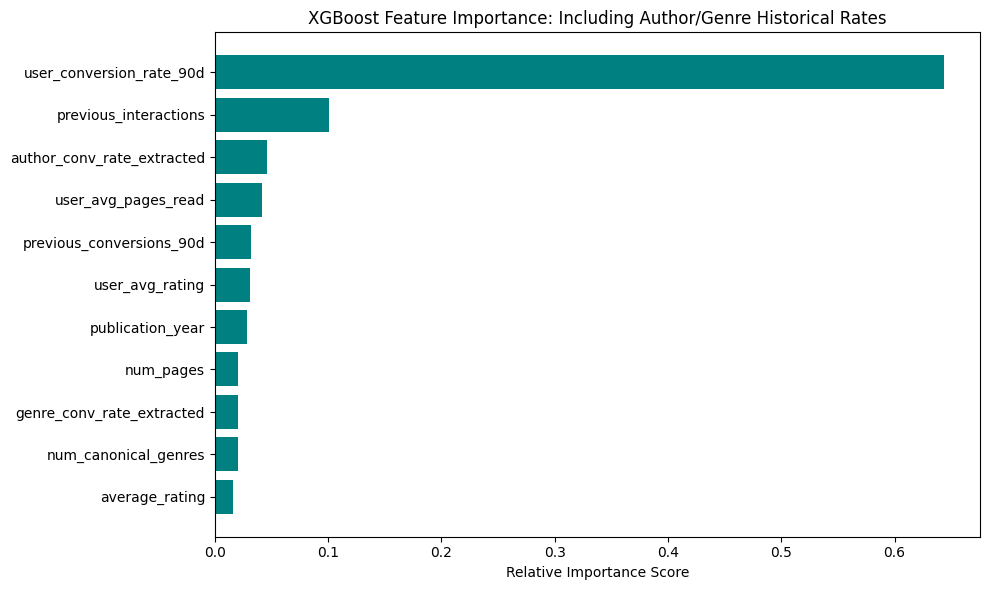

In [9]:
import matplotlib.pyplot as plt

print("--- Updated XGBoost Feature Importance (including Author & Genre conversion rates) ---")

importance_scores = xgb_temporal_model.feature_importances_
#importance_scores = xgb_ranker.feature_importances_...........changed xgboost model
feature_importance_df = pd.DataFrame({
    'Feature': base_features,
    'Importance': importance_scores
}).sort_values(by='Importance', ascending=False)

display(feature_importance_df)

plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='teal')
plt.gca().invert_yaxis()
plt.title('XGBoost Feature Importance: Including Author/Genre Historical Rates')
plt.xlabel('Relative Importance Score')
plt.tight_layout()
plt.show()

Updated Feature Importance Analysis ....xgboost vs xgboost_ranker

,Feature,Classifier_Importance,Ranker_Importance
5,user_conversion_rate_90d,0.585892,0.209085
3,previous_interactions,0.126937,0.117427
0,num_pages,0.024730,0.099566
2,publication_year,0.033414,0.090845
8,num_canonical_genres,0.023573,0.079833
9,genre_conv_rate_extracted,0.037182,0.076688
7,user_avg_pages_read,0.047971,0.076290
1,average_rating,0.019538,0.074007
6,user_avg_rating,0.038251,0.065668
4,previous_conversions_90d,0.042267,0.059826


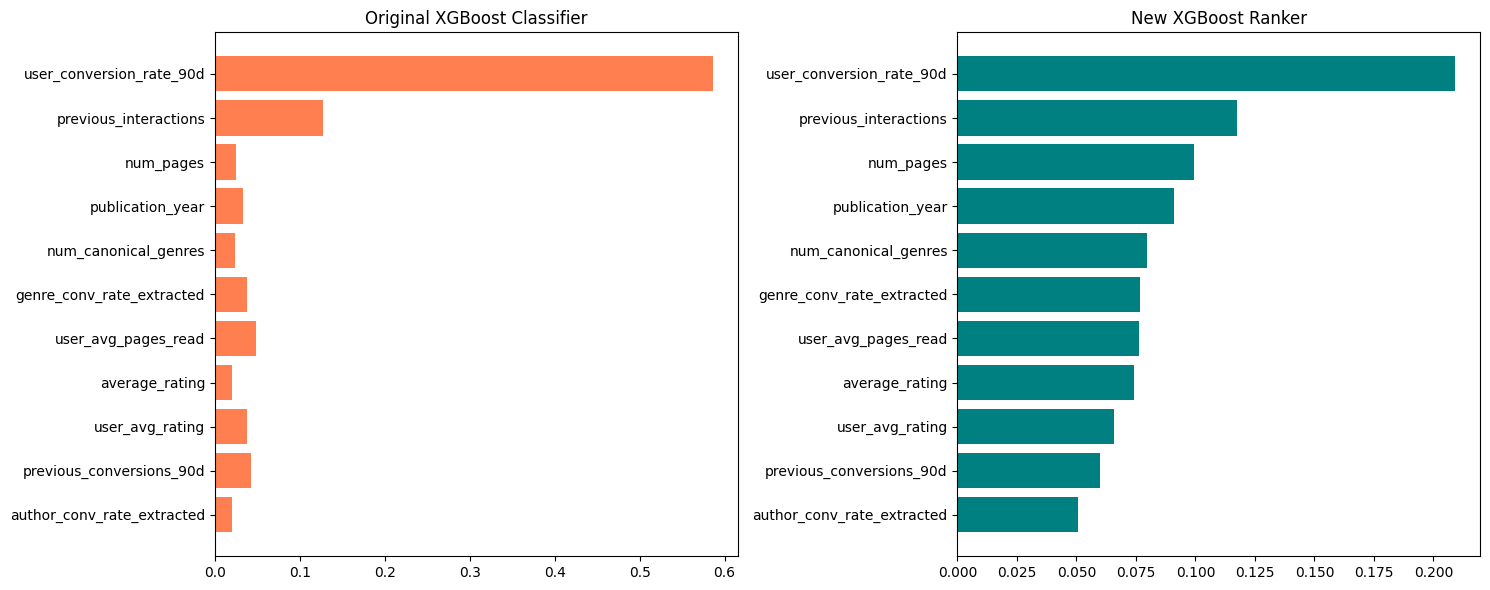

In [61]:
import matplotlib.pyplot as plt

importance_clf = xgb_temporal_model.feature_importances_
importance_ranker = xgb_ranker.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': base_features,
    'Classifier_Importance': importance_clf,
    'Ranker_Importance': importance_ranker
}).sort_values(by='Ranker_Importance', ascending=False)

display(feature_importance_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(feature_importance_df['Feature'], feature_importance_df['Classifier_Importance'], color='coral')
axes[0].invert_yaxis()
axes[0].set_title('Original XGBoost Classifier')

axes[1].barh(feature_importance_df['Feature'], feature_importance_df['Ranker_Importance'], color='teal')
axes[1].invert_yaxis()
axes[1].set_title('New XGBoost Ranker')
plt.tight_layout()
plt.show()

### Update Saved Model and Scaler Assets

In [10]:
# import joblib

# # Save the temporal-split optimized model and the 11-feature scaler
#  joblib.dump(xgb_temporal_model, 'xgboost_conversion_model.pkl')
# # joblib.dump(scaler, 'feature_scaler.pkl')

# # print("Successfully saved updated XGBoost model and Scaler (11 features)!")

Successfully saved updated XGBoost model and Scaler (11 features)!


In [62]:
import joblib

joblib.dump(xgb_temporal_model, 'xgboost_conversion_model.pkl')
joblib.dump(xgb_ranker, 'xgboost_ranker_model.pkl') # ADDED
joblib.dump(scaler, 'feature_scaler_2.pkl')

print("Successfully saved Classifier, Ranker, and Scaler!")

Successfully saved Classifier, Ranker, and Scaler!


### Comparative Ranking Evaluations (NDCG & Recall)

In [11]:
import numpy as np
import pandas as pd

# Helper metric definitions for ranking evaluation
def dcg_at_k(r, k):
    r = np.asarray(r, dtype=float)[:k]
    if r.size:
        return np.sum(r / np.log2(np.arange(2, r.size + 2)))
    return 0.

def ndcg_at_k(r, k):
    dcg_max = dcg_at_k(sorted(r, reverse=True), k)
    if not dcg_max:
        return 0.
    return dcg_at_k(r, k) / dcg_max

def evaluate_recommendations(eval_df, k_values=[5, 10, 20]):
    eval_df = eval_df.sort_values(by=['user_id', 'pred_prob'], ascending=[True, False])
    results = {}
    for k in k_values:
        recalls = []
        ndcgs = []
        conversions = []
        for user, group in eval_df.groupby('user_id'):
            targets = group['target'].values
            total_positives = np.sum(targets)
            if total_positives == 0:
                continue
            top_k_targets = targets[:k]
            pos_in_top_k = np.sum(top_k_targets)
            recalls.append(pos_in_top_k / total_positives)
            ndcgs.append(ndcg_at_k(targets, k))
            conversions.append(1.0 if pos_in_top_k > 0 else 0.0)
        results[f'Recall@{k}'] = np.mean(recalls) if recalls else 0
        results[f'NDCG@{k}'] = np.mean(ndcgs) if ndcgs else 0
        results[f'Conversion@{k}'] = np.mean(conversions) if conversions else 0
    return results

# Prepare evaluation DataFrames using the chronological test indices
test_indices = test_df.index

eval_df_xgb = pd.DataFrame({
    'user_id': df.loc[test_indices, 'user_id'],
    'target': y_test,
    'pred_prob': y_prob
})

eval_df_log = pd.DataFrame({
    'user_id': df.loc[test_indices, 'user_id'],
    'target': y_test,
    'pred_prob': y_prob_log
})

eval_df_rf = pd.DataFrame({
    'user_id': df.loc[test_indices, 'user_id'],
    'target': y_test,
    'pred_prob': y_prob_rf
})

print("Evaluating updated ranking metrics for top recommendations...")
metrics_xgb_k = evaluate_recommendations(eval_df_xgb, k_values=[3, 5, 10, 20])
metrics_log_k = evaluate_recommendations(eval_df_log, k_values=[3, 5, 10, 20])
metrics_rf_k = evaluate_recommendations(eval_df_rf, k_values=[3, 5, 10, 20])

# Construct and display comparison table
comparison_data = {
    'Metric': [],
    'Logistic Regression': [],
    'Random Forest': [],
    'XGBoost': []
}

for k in metrics_xgb_k.keys():
    comparison_data['Metric'].append(k)
    comparison_data['Logistic Regression'].append(f"{metrics_log_k[k]*100:.2f}%")
    comparison_data['Random Forest'].append(f"{metrics_rf_k[k]*100:.2f}%")
    comparison_data['XGBoost'].append(f"{metrics_xgb_k[k]*100:.2f}%")

comparison_df_updated = pd.DataFrame(comparison_data)
display(comparison_df_updated)



#new lines.................


Evaluating updated ranking metrics for top recommendations...


,Metric,Logistic Regression,Random Forest,XGBoost
0,Recall@3,72.20%,75.19%,76.11%
1,NDCG@3,72.43%,77.01%,77.58%
2,Conversion@3,89.58%,92.36%,92.58%
3,Recall@5,87.55%,89.31%,89.30%
4,NDCG@5,77.69%,81.42%,81.59%
5,Conversion@5,96.02%,97.33%,96.94%
6,Recall@10,97.41%,97.72%,97.68%
7,NDCG@10,81.27%,84.32%,84.42%
8,Conversion@10,99.24%,99.40%,99.35%
9,Recall@20,99.51%,99.54%,99.58%


### Probability Calibration, Log Loss, and Brier Score Analysis

In [12]:
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# 1. Compute Brier Score and Log Loss for all models
brier_xgb = brier_score_loss(y_test, y_prob)
log_loss_xgb = log_loss(y_test, y_prob)

brier_log = brier_score_loss(y_test, y_prob_log)
log_loss_log = log_loss(y_test, y_prob_log)

brier_rf = brier_score_loss(y_test, y_prob_rf)
log_loss_rf = log_loss(y_test, y_prob_rf)

# Display summary comparison table
metrics_summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Brier Score (Lower is Better)': [brier_log, brier_rf, brier_xgb],
    'Log Loss (Lower is Better)': [log_loss_log, log_loss_rf, log_loss_xgb]
})

display(metrics_summary)



,Model,Brier Score (Lower is Better),Log Loss (Lower is Better)
0,Logistic Regression,0.190556,0.574651
1,Random Forest,0.175210,0.566670
2,XGBoost,0.174838,0.518550


In [16]:
import pandas as pd
import numpy as np
import joblib

# 1. Load the goodreads_books dataset
print("Loading books dataset...")
books_df = pd.read_csv('../goodreads_books.csv', low_memory=False)

# 2. Pick an active user from the temporal test set
test_users = df.loc[test_df.index, 'user_id'].unique()
target_user = test_users[0]
print(f"Selected User ID for recommendations: {target_user}")

# 3. Extract this user's specific profile from historical data
user_profile = df[df['user_id'] == target_user].iloc[0]

# Deduplicate candidate books
candidate_books = books_df.drop_duplicates(subset=['book_id']).copy()

# 4. Bind the active user properties to the candidate books
candidate_books['user_id'] = target_user
candidate_books['previous_interactions'] = user_profile['previous_interactions']
candidate_books['previous_conversions_90d'] = user_profile['previous_conversions_90d']
candidate_books['user_conversion_rate_90d'] = user_profile['user_conversion_rate_90d']
candidate_books['user_avg_rating'] = user_profile['user_avg_rating']
candidate_books['user_avg_pages_read'] = user_profile['user_avg_pages_read']

# Fill missing variables using training defaults/medians to support the 11-feature model
candidate_books['publication_year'] = pd.to_numeric(candidate_books['publication_year'], errors='coerce')
candidate_books['publication_year'] = candidate_books['publication_year'].fillna(pub_year_median)

candidate_books['average_rating'] = pd.to_numeric(candidate_books['average_rating'], errors='coerce')
candidate_books['average_rating'] = candidate_books['average_rating'].fillna(avg_rating_mean)

candidate_books['num_pages'] = pd.to_numeric(candidate_books['num_pages'], errors='coerce')
candidate_books['num_pages'] = candidate_books['num_pages'].fillna(train_df['num_pages'].median())

if 'num_canonical_genres' not in candidate_books.columns:
    candidate_books['num_canonical_genres'] = 0

# Set default cold start values for newly integrated conversion rates
candidate_books['genre_conv_rate_extracted'] = 0.0
candidate_books['author_conv_rate_extracted'] = 0.0

# 5. Load model & scaler, then run predictions
model = joblib.load('../models/xgboost_conversion_model.pkl')
scaler = joblib.load('../models/feature_scaler.pkl')

# Match exact 11 features expected by the scaler and model
X_cand = candidate_books[base_features]
X_cand_scaled = scaler.transform(X_cand)

candidate_books['pred_prob'] = model.predict_proba(X_cand_scaled)[:, 1]

# 6. Sort and display top 20 recommendations with titles
top_20_recs = candidate_books.sort_values(by='pred_prob', ascending=False).head(20)
display(top_20_recs[['book_id', 'title', 'average_rating', 'num_pages', 'pred_prob']])

Loading books dataset...
Selected User ID for recommendations: 699d351b7d7df4face1fce091a046f2c


C:\Users\emrid\AppData\Local\Programs\Python\Python313\Lib\pickle.py:1760: UserWarning: [19:12:06] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\data\../common/error_msg.h:82: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


,book_id,title,average_rating,num_pages,pred_prob
346926,8007691,ABC Sing-a-Long,3.0,16.0,0.885754
1787602,468569,Peace For All Of Us,3.0,0.0,0.885754
2349531,8700064,Eva the Beekeeper,3.0,16.0,0.885754
890378,15731350,Woof! Woof! A Fun-Packed Sparkly Adventure,3.0,10.0,0.885754
478954,18365448,"Humor voor in de file (Voor in de file, #1)",3.0,1.0,0.885754
1201869,3137838,American Impressionist Paintings: in the Colle...,3.0,16.0,0.885754
1639547,2083696,Picture Pairs!,3.0,8.0,0.885754
1600028,17382577,All Watched Over By Machines of Loving Grace: ...,3.0,18.0,0.885754
762413,30618851,Muumipeikon ystävät,3.0,19.0,0.885754
812566,6440505,The Happy Hippos: Addition (Number Tales),3.0,16.0,0.885754


In [ ]:
# Print one non-empty value of genre_conversion_rates and author_conversion_rates to inspect their structure
non_empty_genre = df[df['genre_conversion_rates'].notna() & (df['genre_conversion_rates'] != '[]')]['genre_conversion_rates'].iloc[0]
non_empty_author = df[df['author_conversion_rates'].notna() & (df['author_conversion_rates'] != '[]')]['author_conversion_rates'].iloc[0]

print("=== Raw Genre Conversion Rates Format ===")
print(non_empty_genre)
print("\n=== Raw Author Conversion Rates Format ===")
print(non_empty_author)

In [ ]:
# Let's inspect the specific genres and authors of the top recommended books to understand the recommendations better.
# We will pull additional metadata fields from the books_df for these top 20 book IDs.
top_20_book_ids = top_20_recs['book_id'].tolist()

# Filter books_df to inspect additional details of these top 20 recommended books
recommended_books_details = books_df[books_df['book_id'].isin(top_20_book_ids)][[
    'book_id', 'title', 'author_names', 'average_rating', 'num_pages', 'publication_year', 'genres'
]]

# Merge with our prediction probabilities to display them sorted by prediction confidence
recommended_books_details = recommended_books_details.merge(
    top_20_recs[['book_id', 'pred_prob']], on='book_id'
).sort_values(by='pred_prob', ascending=False)

display(recommended_books_details)

In [ ]:
# Calculate SHAP explanations for each individual recommended book to provide model-based reasons
import numpy as np
import pandas as pd
import shap
import joblib

# Initialize SHAP explainer on our trained XGBoost model
explainer = shap.TreeExplainer(model)

# Match exact 11 features expected by the scaler and model
X_cand_recs = top_20_recs[base_features]
X_cand_recs_scaled = scaler.transform(X_cand_recs)

# Compute SHAP values for these top recommendations
recs_shap_values = explainer.shap_values(X_cand_recs_scaled)

# Apply custom formatting to turn SHAP outputs into plain English reasons
def get_shap_explanation(shap_row, raw_row, feature_names):
    # Sort features by absolute contribution
    sorted_indices = np.argsort(np.abs(shap_row))[::-1]
    reasons = []

    for idx in sorted_indices[:3]: # Explain using top 3 contributing features
        feat_name = feature_names[idx]
        val = raw_row[feat_name]
        contribution = shap_row[idx]

        direction = "increased likelihood" if contribution > 0 else "decreased likelihood"
        reasons.append(f"{feat_name} ({val}) {direction} by {abs(contribution):.2f}")

    return " • " + "\n • ".join(reasons)

# Re-construct our recommended books table with SHAP-based explanations
explanation_df = top_20_recs.copy().reset_index(drop=True)
shap_reasons = []
for i, row in explanation_df.iterrows():
    explanation = get_shap_explanation(recs_shap_values[i], row, base_features)
    shap_reasons.append(explanation)

explanation_df['Recommendation Explanation'] = shap_reasons

# Display the top recommendations accompanied by model-intrinsic SHAP reasons
for idx, row in explanation_df.iterrows():
    print(f"=== Rank {idx+1}: {row['title']} (Prob: {row['pred_prob']:.4f}) ===")
    print(row['Recommendation Explanation'])
    print("-" * 80 + "\n")

In [60]:
# Create a separate dataframe for the ranker's candidate predictions
candidate_books_ranker = candidate_books.copy()

# Scale features and predict using the ranker
X_cand_rank = scaler.transform(candidate_books_ranker[base_features])
candidate_books_ranker['pred_score'] = xgb_ranker.predict(X_cand_rank)

# Sort by the new pred_score and display
top_20_ranker = candidate_books_ranker.sort_values(by='pred_score', ascending=False).head(20)

print(f"Top 20 XGBRanker Recommendations for User: {target_user}")
display(top_20_ranker[['book_id', 'title', 'average_rating', 'num_pages', 'pred_score']])

Top 20 XGBRanker Recommendations for User: bc1bed09c182d6c97192d1a121984e67


,book_id,title,average_rating,num_pages,pred_score
994576,26522978,To Rise Again at a Decent Hour,3.08,10.0,0.829859
1344715,20920026,The Evil Clergyman,3.02,8.0,0.829859
1847961,33236514,Valmanifest för Piratpartiet EU-valet 2014,3.00,6.0,0.829859
1991589,17261659,"Artificial Lover (Artificial Love Stories, #1)",2.75,10.0,0.829859
1543342,22878443,YES,2.90,1.0,0.829859
977387,28691416,Thought I'd Let You Know...,2.00,6.0,0.829859
1145606,22822240,"Evening Rounds (Outsider, #2)",2.71,5.0,0.829859
727760,23733463,Istanti Smembrati,2.33,11.0,0.829859
110048,20920046,The Tree,2.98,7.0,0.829859
797158,22584655,Spots and Dots!,2.67,6.0,0.829859


In [64]:
import json
import ast

# 4. Bind active user properties
for col in ['previous_interactions', 'previous_conversions_90d', 'user_conversion_rate_90d', 'user_avg_rating', 'user_avg_pages_read']:
    candidate_books[col] = user_profile[col]

candidate_books['publication_year'] = pd.to_numeric(candidate_books['publication_year'], errors='coerce').fillna(pub_year_median)
candidate_books['average_rating'] = pd.to_numeric(candidate_books['average_rating'], errors='coerce').fillna(avg_rating_mean)
candidate_books['num_pages'] = pd.to_numeric(candidate_books['num_pages'], errors='coerce').fillna(train_df['num_pages'].median())
candidate_books['num_canonical_genres'] = candidate_books.get('num_canonical_genres', 0)

# DYNAMIC LOOKUP to fix identical score bug
user_author_hist = json.loads(user_profile.get('author_conversion_rates', '[]') or '[]')
user_genre_hist = json.loads(user_profile.get('genre_conversion_rates', '[]') or '[]')
author_map = {str(i['key']): float(i['conversion_rate']) for i in user_author_hist if isinstance(i, dict)}
genre_map = {str(i['key']): float(i['conversion_rate']) for i in user_genre_hist if isinstance(i, dict)}

def get_max_rate(val_str, mapping):
    try:
        items = ast.literal_eval(val_str) if isinstance(val_str, str) else ([val_str] if pd.notna(val_str) else [])
        rates = [mapping.get(str(i).lower() if 'genre' in str(mapping) else str(i), 0.0) for i in items]
        return max(rates) if rates else 0.0
    except: return 0.0

candidate_books['author_conv_rate_extracted'] = candidate_books['author_ids'].apply(lambda x: get_max_rate(x, author_map))
candidate_books['genre_conv_rate_extracted'] = candidate_books['genres'].apply(lambda x: get_max_rate(x, genre_map))

# Filter to books with historical signal to allow Ranker to work
filtered_cands = candidate_books[(candidate_books['author_conv_rate_extracted'] > 0) | (candidate_books['genre_conv_rate_extracted'] > 0)].copy()
if len(filtered_cands) < 20: filtered_cands = candidate_books.copy()

# 5. Load both models and scale
model_clf = joblib.load('xgboost_conversion_model.pkl')
model_rnk = joblib.load('xgboost_ranker_model.pkl')
scaler = joblib.load('feature_scaler.pkl')

X_cand_scaled = scaler.transform(filtered_cands[base_features])

# Predict with both
filtered_cands['prob_classifier'] = model_clf.predict_proba(X_cand_scaled)[:, 1]
filtered_cands['score_ranker'] = model_rnk.predict(X_cand_scaled)

# 6. Display Comparisons
print("\n--- Top 10 by Original XGBClassifier ---")
display(filtered_cands.sort_values(by='prob_classifier', ascending=False).head(10)[['book_id', 'title', 'prob_classifier']])

print("\n--- Top 10 by New XGBRanker ---")
display(filtered_cands.sort_values(by='score_ranker', ascending=False).head(10)[['book_id', 'title', 'score_ranker']])


--- Top 10 by Original XGBClassifier ---


,book_id,title,prob_classifier
591898,24292209,The Great Governing Families of England. 2v.,0.984705
124281,6172281,Geraldine First,0.984705
2182504,7146595,Grandfather Was Queer: Wags and Eccentrics in ...,0.984705
2323395,4099319,"The Riddle Club at Home (The Riddle Club, #1)",0.984705
1071362,22614166,Hellerbochen's Dilemma,0.984705
1819018,1528639,They Went to Portugal,0.984705
1606596,20755501,The Physiologist; or Sexual Physiology Revealed,0.984705
618323,8320471,"Selected poems of William Alexander, archbisho...",0.984705
1415258,18040337,Murder in the Glass Room,0.984705
2033882,6847290,Essays. Chosen and edited with a pref. and a f...,0.984705



--- Top 10 by New XGBRanker ---


,book_id,title,score_ranker
2291374,6453331,Whispers in the Dark,1.740258
2217117,45161,The Roald Dahl Audio Collection,1.740258
1449210,11454645,Billy: The Untold Story of a Young Billy Graha...,1.740258
407859,20427156,The Collected Stories of Winnie-The-Pooh,1.740258
113886,4134017,Safely Home,1.740258
1578299,13411984,Game of Thrones - Das Lied von Eis und Feuer 6,1.740258
780137,6068142,Tales Told By Moonlight,1.740258
1119815,3539275,Twisted Fayrie Tales Anthology,1.740258
1062826,3980549,Exhibition,1.740258
2255827,4799843,Through the Dark Wood: Finding Meaning in the ...,1.740258


Generating SHAP explanations for the New XGBRanker...


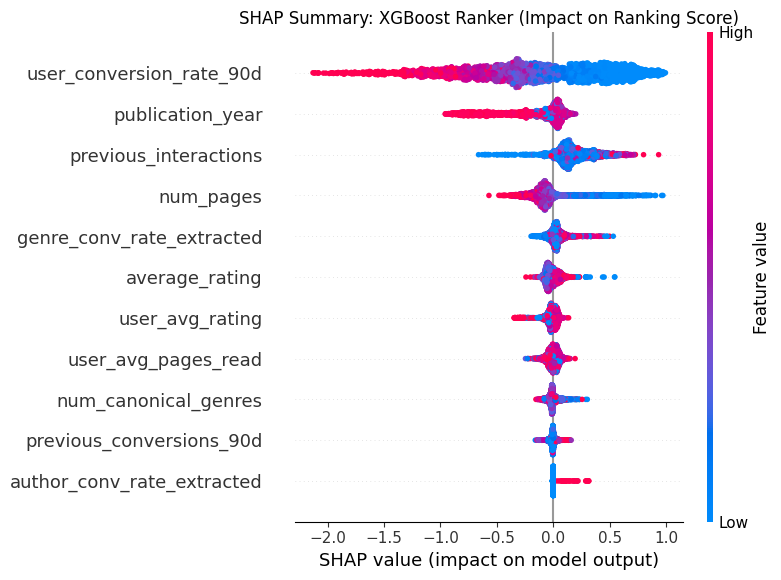

Generating SHAP explanations for the Original XGBClassifier...


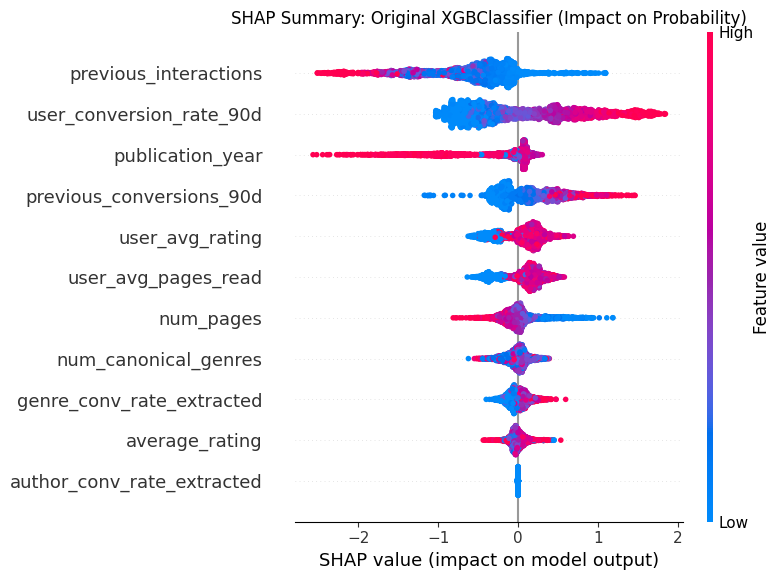

In [65]:
import shap
import matplotlib.pyplot as plt

# Use a sample of the test set to compute SHAP values quickly (prevents memory crashes)
X_test_sample = X_test_rank[:3000]

# --- 1. SHAP for the New XGBRanker ---
print("Generating SHAP explanations for the New XGBRanker...")
explainer_rnk = shap.TreeExplainer(xgb_ranker)
shap_values_rnk = explainer_rnk.shap_values(X_test_sample)

plt.figure()
plt.title("SHAP Summary: XGBoost Ranker (Impact on Ranking Score)")
shap.summary_plot(shap_values_rnk, X_test_sample, feature_names=base_features, show=False)
plt.tight_layout()
plt.show()

# --- 2. SHAP for the Original XGBClassifier ---
print("Generating SHAP explanations for the Original XGBClassifier...")
explainer_clf = shap.TreeExplainer(xgb_temporal_model)
shap_values_clf = explainer_clf.shap_values(X_test_sample)

plt.figure()
plt.title("SHAP Summary: Original XGBClassifier (Impact on Probability)")
shap.summary_plot(shap_values_clf, X_test_sample, feature_names=base_features, show=False)
plt.tight_layout()
plt.show()